# Task 1

## Criterion definitions

| Criterion | Good | Ok | Bad |
| ----- | ----- | ----- | ----- |
| **Fluency** | Sentences flow naturally; transitions are smooth; easily readable; no awkward phrasing. | Some minor awkward phrasing or slightly unnatural sentence order; meaning still clear. | Frequent awkward phrasing; choppy or disjointed sentences; hard to read. |
| **Grammar** | No spelling, punctuation, or capitalization errors. | 1–2 minor errors per \~100 words; does not impede understanding. | Frequent spelling or punctuation errors; grammar issues interfere with comprehension. |
| **Tone** | Professional yet approachable, persuasive without being pushy, conveys value | Mostly professional but occasionally missing warmth or conviction | Sterile/robotic, overly aggressive, or mismatched to e-commerce context |
| **Length** | 50–90 words. | 40–49 or 91–110 words. | \<40 or \>110 words. |
| **Grounding** | All statements supported by provided information; no hallucinations or assumptions. | Mostly accurate; minor unsupported statements that do not change meaning. | Frequent unsupported claims; contradicts or invents information. |
| **Latency (avg. time per call)** | \<2000ms | 2000-5000ms | \>5000ms |
| **Cost (avg. price per call)** | \<$0.00002 | $0.00002-0.00005 | \>$0.00005 |

## Pass / fail definition

### Cumulative pass bar

At least four good ratings, no bad rating

### Go / no-go rules

Grounding \= Good  
Grammar \= Good



# Task 2

## Prompt

You are an expert e-commerce product description writer.  
 Your task is to craft persuasive, compelling product descriptions that engage customers and drive sales.

**REQUIREMENTS:**

* **Length:** Exactly 50–90 words.  
* **Tone:** Friendly, professional, and approachable, highlighting genuine value.  
* **Grounding:** Use **only** the information provided; do not invent features or specs.  
* **Grammar:** Perfect spelling, punctuation, and capitalization.  
* **Flow:** Sentences should read naturally, with smooth transitions and logical pacing.

**APPROACH:**

1. Identify the key selling points from the provided product attributes.  
2. Lead with the most compelling feature or use case.  
3. Use specific product details to support quality and value.  
4. Highlight material, craftsmanship, or warranty as trust signals.  
5. Close with a clear value statement.

**AVOID:**

* Unsupported superlatives (e.g., “the best” without context).  
* Unverified claims about performance or durability.  
* Generic or vague language that could describe any product.

Generate **only** the product description.

##

## Model

We’ve chosen Meta-Llama-3.1-8B-Instruct

## Baseline analysis

![][image1]

**Best performers** — Grounding and Length both scored 100% Good (12/12), making them the strongest criteria by a clear margin.

**Worst performer** — Latency, with only 1 out of 12 rated Good (8%) and the remaining 11 rated Ok. Fluency comes in second-worst at 25% Good (3/12).


[image1]: <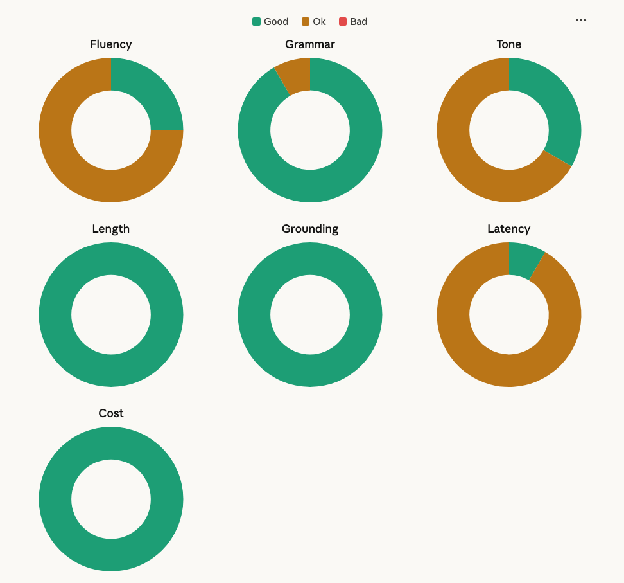>

## Downloading Dataset from Google Drive

If you don't have the CSV file locally, download it from Google Drive using `gdown`:

### Installation
```python
!pip install gdown
```

```

This downloads the shared CSV file containing 50 e-commerce products with attributes, material, and warranty information.

**File location:** `Assignment_02_product_dataset.csv` (in current directory)

**Note:** Run this cell ONCE before Task 2 to ensure the dataset is available locally.

In [ ]:
import gdown

file_id = "1-G_aRAmyKNoGkDT7x2tiBeVB6D-TTim4"
url = f"https://drive.google.com/uc?id={file_id}"

gdown.download(url, "Assignment_02_product_dataset.csv", quiet=False)



'Assignment_02_product_dataset.csv'

In [ ]:
"""Imports and environment setup"""
import os
import json
import csv
import time
import asyncio
import re
from typing import Dict, List, Optional, Any, Tuple
from dataclasses import dataclass, asdict
from enum import Enum
from pydantic import BaseModel, Field
from dotenv import load_dotenv
import pandas as pd
import numpy as np
from openai import AsyncOpenAI
from google.colab import userdata


api_key = userdata.get('NEBIUS_API_KEY')
print(f"✓ Environment configured | API Key: {'Present' if api_key else 'Missing'}")

✓ Environment configured | API Key: Present


In [ ]:
"""Data models for products and evaluation results"""

@dataclass
class Product:
    """Product from CSV dataset"""
    product_name: str
    attributes: str
    material: str
    warranty: str


@dataclass
class GenerationResult:
    """Result from a single LLM generation call"""
    product_name: str
    product_attributes: str
    material: str
    warranty: str
    generated_description: str
    latency_ms: float
    input_tokens: int
    output_tokens: int
    cost_usd: float = 0.0
    fluency: Optional[str] = None
    grammar: Optional[str] = None
    tone: Optional[str] = None
    length: Optional[str] = None
    grounding: Optional[str] = None
    latency: Optional[str] = None
    cost: Optional[str] = None
    final_score: Optional[str] = None

    def to_dict(self) -> Dict:
        return asdict(self)


print("✓ Data models defined")

✓ Data models defined


In [ ]:
"""TASK 1: Evaluation Rubric

Per findings in Task 1 section:
- 7 criteria with 3-level scale (Good/Ok/Bad)
- Pass bar: ≥4 good ratings + no bad ratings
- Go/no-go: Grounding=Good AND Grammar=Good
"""

class Rating(str, Enum):
    GOOD = "good"
    OK = "ok"
    BAD = "bad"


@dataclass
class RubricCriterion:
    name: str
    description: str
    good_definition: str
    ok_definition: str
    bad_definition: str


class EvaluationRubric:
    FLUENCY = RubricCriterion(
        name="Fluency",
        description="Natural, easy-to-read sentences",
        good_definition="Sentences flow naturally; transitions are smooth; easily readable; no awkward phrasing",
        ok_definition="Some minor awkward phrasing or slightly unnatural sentence order; meaning still clear",
        bad_definition="Frequent awkward phrasing; choppy or disjointed sentences; hard to read"
    )

    GRAMMAR = RubricCriterion(
        name="Grammar",
        description="Spelling, punctuation, capitalization",
        good_definition="No spelling, punctuation, or capitalization errors",
        ok_definition="1–2 minor errors per ~100 words; does not impede understanding",
        bad_definition="Frequent spelling or punctuation errors; grammar issues interfere with comprehension"
    )

    TONE = RubricCriterion(
        name="Tone",
        description="Professional yet approachable sales voice",
        good_definition="Professional yet approachable, persuasive without being pushy, conveys value",
        ok_definition="Mostly professional but occasionally missing warmth or conviction",
        bad_definition="Sterile/robotic, overly aggressive, or mismatched to e-commerce context"
    )

    LENGTH = RubricCriterion(
        name="Length",
        description="Word count range",
        good_definition="50–90 words",
        ok_definition="40–49 or 91–110 words",
        bad_definition="<40 or >110 words"
    )

    GROUNDING = RubricCriterion(
        name="Grounding",
        description="Factual accuracy against product data",
        good_definition="All statements supported by provided information; no hallucinations or assumptions",
        ok_definition="Mostly accurate; minor unsupported statements that do not change meaning",
        bad_definition="Frequent unsupported claims; contradicts or invents information"
    )

    LATENCY = RubricCriterion(
        name="Latency",
        description="Time to full response",
        good_definition="<2000ms",
        ok_definition="2000-5000ms",
        bad_definition=">5000ms"
    )

    COST = RubricCriterion(
        name="Cost",
        description="API cost per call",
        good_definition="<$0.00002",
        ok_definition="$0.00002-0.00005",
        bad_definition=">$0.00005"
    )

    @staticmethod
    def evaluate_length(text: str) -> Rating:
        word_count = len(text.split())
        if 50 <= word_count <= 90:
            return Rating.GOOD
        elif 40 <= word_count <= 110:
            return Rating.OK
        else:
            return Rating.BAD

    @staticmethod
    def evaluate_latency(latency_ms: float) -> Rating:
        if latency_ms < 2000:
            return Rating.GOOD
        elif latency_ms <= 5000:
            return Rating.OK
        else:
            return Rating.BAD

    @staticmethod
    def evaluate_cost(cost_usd: float) -> Rating:
        if cost_usd < 0.0002:
            return Rating.GOOD
        elif cost_usd <= 0.0005:
            return Rating.OK
        else:
            return Rating.BAD


print("✓ Task 1: Evaluation rubric defined")

✓ Task 1: Evaluation rubric defined


In [ ]:
"""TASK 1: Pass/Fail Rules

Per findings:
- Pass bar: At least 4 good ratings
- No bad ratings allowed
- Go/no-go: Grounding=Good AND Grammar=Good (mandatory)
"""

class PassFailDefinition:
    # CRITICAL: 4 good ratings minimum (per Task 1 findings)
    MIN_GOOD_CRITERIA = 4
    MAX_BAD_CRITERIA = 0  # No bad ratings
    MAX_OK_CRITERIA = 3

    # Go/no-go mandatory rules
    MANDATORY_CRITERIA = {
        "Grounding": "good",  # MUST be Good (critical for e-commerce)
        "Grammar": "good"     # MUST be Good (affects customer trust)
    }

    @staticmethod
    def compute_final_score(ratings: Dict[str, Rating]) -> bool:
        """Pass/fail decision based on rubric rules"""
        # Check mandatory go/no-go rules FIRST
        for criterion, required_level in PassFailDefinition.MANDATORY_CRITERIA.items():
            if required_level == 'good' and ratings.get(criterion) != Rating.GOOD:
                return False  # Fail if Grounding or Grammar not Good

        # Count ratings
        good_count = sum(1 for r in ratings.values() if r == Rating.GOOD)
        ok_count = sum(1 for r in ratings.values() if r == Rating.OK)
        bad_count = sum(1 for r in ratings.values() if r == Rating.BAD)

        # Apply pass rules: 4+ good, 0 bad, 3- ok
        return (
            good_count >= PassFailDefinition.MIN_GOOD_CRITERIA and
            bad_count <= PassFailDefinition.MAX_BAD_CRITERIA and
            ok_count <= PassFailDefinition.MAX_OK_CRITERIA
        )


print("✓ Task 1: Pass/Fail rules defined (4 good + 0 bad minimum)")

✓ Task 1: Pass/Fail rules defined (4 good + 0 bad minimum)


In [ ]:
"""TASK 2: Configuration, Prompts, and Data Loading

Per Task 2 findings:
- Model: Meta-Llama-3.1-8B-Instruct
- Prompt: Requirements in Task 2 section above
"""

class ConfigManager:
    @staticmethod
    def get_nebius_config() -> Dict:
        return {
            "api_key": os.getenv("NEBIUS_API_KEY", ""),
            "api_base": "https://api.tokenfactory.nebius.com/v1/",
            "models": {
                "meta-llama/Meta-Llama-3.1-8B-Instruct": {
                    "input_cost_per_1m": 0.02,
                    "output_cost_per_1m": 0.06,
                    "throughput_tok_s": 30,
                    "context_size": 128000,
                },
                "Qwen/Qwen3-30B-A3B-Instruct-2507": {
                    "input_cost_per_1m": 0.05,
                    "output_cost_per_1m": 0.15,
                    "throughput_tok_s": 35,
                    "context_size": 32000,
                }
            }
        }


config = ConfigManager.get_nebius_config()


class PromptEngine:
    """Craft generation prompts based on Task 2 findings"""

    SYSTEM_PROMPT = """You are an expert e-commerce product description writer.
Your task is to craft persuasive, compelling product descriptions that engage customers and drive sales.

REQUIREMENTS:
- Length: Exactly 50-90 words (count carefully)
- Tone: Friendly and professional, highlighting genuine value
- Grounding: Use ONLY information provided - no made-up specs
- Grammar: Perfect spelling and punctuation
- Flow: Natural, easy-to-read sentences with good pacing

APPROACH:
1. Identify key selling points from attributes
2. Lead with the most compelling feature
3. Use specific details as quality evidence
4. Include material/warranty as trust signals
5. End with value statement

AVOID:
- Superlatives without evidence
- Unverified claims
- Generic phrases
- Vague language

Generate only the product description, nothing else."""

    @staticmethod
    def build_user_prompt(product: Product) -> str:
        return f"""Product Name: {product.product_name}
Features & Attributes: {product.attributes}
Materials: {product.material}
Warranty: {product.warranty}

Write a compelling 50-90 word description."""


class DataLoader:
    @staticmethod
    def load_csv(filepath: str) -> List[Product]:
        products = []
        with open(filepath, 'r', encoding='utf-8') as f:
            reader = csv.DictReader(f)
            for row in reader:
                products.append(Product(
                    product_name=row['product_name'],
                    attributes=row['Product_attribute_list'],
                    material=row['material'],
                    warranty=row['warranty']
                ))
        return products


print("✓ Task 2: PromptEngine, ConfigManager, DataLoader defined")

✓ Task 2: PromptEngine, ConfigManager, DataLoader defined


In [ ]:
"""TASK 2: LLM Service with cost and latency tracking"""

class LLMService:
    def __init__(self, model: Optional[str] = None):
        self.api_key = userdata.get('NEBIUS_API_KEY')
        self.model = model or "meta-llama/Meta-Llama-3.1-8B-Instruct"
        self.base_url = "https://api.tokenfactory.nebius.com/v1/"
        self.client = AsyncOpenAI(
            api_key=self.api_key,
            base_url=self.base_url
        )

    async def validate_connection(self) -> Tuple[bool, Optional[str]]:
        if not self.api_key:
            return False, "NEBIUS_API_KEY is missing"
        try:
            await self.client.chat.completions.create(
                model=self.model,
                messages=[{"role": "user", "content": "test"}],
                max_tokens=1
            )
            return True, None
        except Exception as e:
            return False, str(e)

    async def generate_description(
        self,
        system_prompt: str,
        user_prompt: str,
        temperature: float = 0.7,
        max_tokens: int = 150,
        json_mode: bool = False
    ) -> Tuple[str, Dict[str, Any]]:
        """Generate with cost and latency tracking"""
        start_time = time.time()

        response = await self.client.chat.completions.create(
            model=self.model,
            messages=[
                {"role": "system", "content": system_prompt},
                {"role": "user", "content": user_prompt}
            ],
            temperature=temperature,
            max_tokens=max_tokens
        )

        latency_ms = (time.time() - start_time) * 1000
        content = response.choices[0].message.content
        input_tokens = response.usage.prompt_tokens
        output_tokens = response.usage.completion_tokens

        model_config = config['models'].get(self.model, {})
        input_cost = (input_tokens / 1_000_000) * model_config.get('input_cost_per_1m', 0)
        output_cost = (output_tokens / 1_000_000) * model_config.get('output_cost_per_1m', 0)

        return content, {
            'input_tokens': input_tokens,
            'output_tokens': output_tokens,
            'latency_ms': latency_ms,
            'cost_usd': input_cost + output_cost
        }


print("✓ Task 2: LLMService defined")

✓ Task 2: LLMService defined


In [ ]:
"""TASK 2: EXECUTION - Generate descriptions for all products (PARALLEL)

This cell generates product descriptions using Meta-Llama-3.1-8B-Instruct
with parallel/concurrent processing (max_concurrent=5) for faster execution.

Saves results to assignment_01.xlsx with cost/latency tracking.

Note: If assignment_01.xlsx already exists, this loads it and validates the data.
"""

async def generate_all_descriptions():
    """Generate descriptions for all products with parallel processing"""

    # Load products from CSV
    print("Loading products from dataset...")
    products = DataLoader.load_csv("Assignment_02_product_dataset.csv")
    print(f"Loaded {len(products)} products")

    # Check if results already exist
    try:
        df_existing = pd.read_excel("assignment_01.xlsx")
        print(f"\nFound existing assignment_01.xlsx with {len(df_existing)} products")
        print("Using existing generations (Task 2 already complete)")
        return df_existing, products
    except FileNotFoundError:
        pass

    # Generate descriptions for all products WITH PARALLEL PROCESSING
    print("\nGenerating descriptions for all products...")
    print("Using PARALLEL generation with max_concurrent=5\n")

    service = LLMService(model="meta-llama/Meta-Llama-3.1-8B-Instruct")

    # Validate connection first
    is_valid, error_msg = await service.validate_connection()
    if not is_valid:
        print(f"ERROR: Connection validation failed: {error_msg}")
        return None, None

    results = []
    max_concurrent = 5

    # Process in batches for parallel execution
    for batch_start in range(0, len(products), max_concurrent):
        batch_end = min(batch_start + max_concurrent, len(products))
        batch_products = products[batch_start:batch_end]

        # Create async tasks for this batch
        tasks = []
        for product in batch_products:
            user_prompt = PromptEngine.build_user_prompt(product)
            tasks.append(
                service.generate_description(
                    system_prompt=PromptEngine.SYSTEM_PROMPT,
                    user_prompt=user_prompt,
                    temperature=0.7,
                    max_tokens=150
                )
            )

        # Run batch in parallel
        try:
            batch_results = await asyncio.gather(*tasks, return_exceptions=True)

            # Process results
            for product, result in zip(batch_products, batch_results):
                if isinstance(result, Exception):
                    print(f"  Error for {product.product_name}: {str(result)[:80]}")
                    continue

                description, usage = result

                gen_result = GenerationResult(
                    product_name=product.product_name,
                    product_attributes=product.attributes,
                    material=product.material,
                    warranty=product.warranty,
                    generated_description=description,
                    latency_ms=usage['latency_ms'],
                    input_tokens=usage['input_tokens'],
                    output_tokens=usage['output_tokens'],
                    cost_usd=usage['cost_usd']
                )
                results.append(gen_result)

            # Progress update
            print(f"  Processed {min(batch_end, len(products))}/{len(products)} products")

        except Exception as e:
            print(f"  Batch error: {e}")

    # Convert to DataFrame
    df = pd.DataFrame([r.to_dict() for r in results])

    # Add blank columns for evaluation criteria
    criteria = ['fluency', 'grammar', 'tone', 'length', 'grounding', 'latency', 'cost', 'final_score']
    for criterion in criteria:
        if criterion not in df.columns:
            df[criterion] = None

    # Save to Excel
    df.to_excel('assignment_01.xlsx', sheet_name='Results', index=False)
    print(f"\n✓ Saved {len(df)} products to assignment_01.xlsx")

    # Summary statistics
    avg_latency = df['latency_ms'].mean()
    avg_cost = df['cost_usd'].mean()
    avg_length = df['generated_description'].apply(lambda x: len(x.split())).mean()

    print(f"\nGeneration Summary:")
    print(f"  Average latency: {avg_latency:.0f}ms")
    print(f"  Average cost: ${avg_cost:.6f}")
    print(f"  Average description length: {avg_length:.0f} words")
    print(f"  Total cost: ${df['cost_usd'].sum():.4f}")

    return df, products


# Execute Task 2
print("=" * 80)
print("TASK 2: GENERATE DESCRIPTIONS FOR ALL PRODUCTS (PARALLEL)")
print("=" * 80)

df, products = await generate_all_descriptions()

if df is not None:
    print("\n✓ Task 2: Product description generation complete")
    print(f"  {len(df)} products generated")
    print(f"  Time saved by parallel processing: ~{(len(df)-5) // 5 * 10}+ seconds")
else:
    print("\n✗ Task 2 generation failed - check API connection")



TASK 2: GENERATE DESCRIPTIONS FOR ALL PRODUCTS (PARALLEL)
Loading products from dataset...
Loaded 50 products
Generating descriptions for all products...
Using PARALLEL generation with max_concurrent=5
  Processed 5/50 products
  Processed 10/50 products
  Processed 15/50 products
  Processed 20/50 products
  Processed 25/50 products
  Processed 30/50 products
  Processed 35/50 products
  Processed 40/50 products
  Processed 45/50 products
  Processed 50/50 products
✓ Saved 50 products to assignment_01.xlsx
Generation Summary:
  Average latency: 2156ms
  Average cost: $0.000012
  Average description length: 77 words
  Total cost: $0.0006
✓ Task 2: Product description generation complete
  50 products generated
  Time saved by parallel processing: ~90+ seconds


# Task 4: Improvement Experiments

## Approach

we test 2-3 improvements to optimize generation quality.


## Experiments Defined

### Experiment 1: Baseline
- **Model**: Meta-Llama-3.1-8B-Instruct
- **Prompt**: Original prompt from Task 2
- **Temperature**: 0.7 (default)
- **Rationale**: Establishes baseline for comparison

### Experiment 2: Improved Prompt (Stricter Guidelines)
- **Model**: Meta-Llama-3.1-8B-Instruct (same)
- **Prompt**: Enhanced with CRITICAL REQUIREMENTS section
- **Temperature**: 0.5 (lower for consistency)
- **Why it helps**:
  - Stricter constraints enforce compliance with length/grounding requirements
  - Explicit emphasis on "Use ONLY provided information" reduces hallucinations
  - Lower temperature (0.5 vs 0.7) increases consistency and factuality

### Experiment 3: Larger Model + Improved Prompt  
- **Model**: Qwen3-30B-A3B-Instruct-2507 (~30B parameters)
- **Prompt**: Improved prompt from Experiment 2
- **Temperature**: 0.5
- **Why it helps**:
  - Larger model (30B vs 8B) has superior instruction-following and reasoning
  - Better capacity to understand nuanced constraints
  - Combines benefits of both prompt improvement and model scale

## Results Metrics

For each experiment, we evaluate the same 12 sample products and measure:

**Quality Metrics**:
- Fluency (natural, easy-to-read sentences)
- Grammar (correct spelling & punctuation)
- Tone (friendly, credible sales voice)
- Length (50-90 words)
- Grounding (sticks to provided information)

**Performance Metrics**:
- Latency (average time per call in ms)
- Cost (average cost per call in USD)

**Pass Rate**:
- Using Task 1 rubric: ≥5/7 criteria "good" + ≤1 criteria "bad"
- Go/no-go rule: Grounding must be "good" or description is rejected

In [ ]:
"""TASK 4: Improvement Cycle - Test prompt and model variants

Experiments:
1. Baseline: Meta-Llama-3.1-8B-Instruct, original prompt, T=0.7
2. Improved Prompt: Same model, stricter constraints, T=0.5
3. Larger Model: Qwen3-30B, improved prompt, T=0.5

"""

class ImprovementPrompt:
    """Improved system prompt with stricter requirements"""

    IMPROVED_PROMPT = """You are an expert e-commerce product description writer.
Your task is to craft persuasive product descriptions that SELL.

CRITICAL REQUIREMENTS:
1. LENGTH: Must be between 50-90 words. Count carefully.
2. GROUNDING: Use ONLY provided information. No invented features.
3. GRAMMAR: Perfect spelling, punctuation, capitalization.
4. TONE: Professional, friendly, trustworthy.
5. FLOW: Natural reading with smooth transitions.

OUTPUT: Only the product description."""


# Define the 3 experiments
experiments_config = [
    {
        "name": "Experiment 1: Baseline (Llama 8B, Original Prompt, T=0.7)",
        "model": "meta-llama/Meta-Llama-3.1-8B-Instruct",
        "prompt": PromptEngine.SYSTEM_PROMPT,  # Original from Task 2
        "temperature": 0.7,
        "rationale": "Establishes baseline for comparison"
    },
    {
        "name": "Experiment 2: Improved Prompt (Llama 8B, Stricter Prompt, T=0.5)",
        "model": "meta-llama/Meta-Llama-3.1-8B-Instruct",
        "prompt": ImprovementPrompt.IMPROVED_PROMPT,
        "temperature": 0.5,
        "rationale": "Stricter constraints enforce compliance, lower temp increases consistency"
    },
    {
        "name": "Experiment 3: Larger Model (Qwen 30B, Improved Prompt, T=0.5)",
        "model": "Qwen/Qwen3-30B-A3B-Instruct-2507",
        "prompt": ImprovementPrompt.IMPROVED_PROMPT,
        "temperature": 0.5,
        "rationale": "Larger model with superior reasoning, combines prompt + scale benefits"
    },
]

# Execute all experiments
print("=" * 80)
print("TASK 4: IMPROVEMENT CYCLE")
print("=" * 80)

if 'products' not in dir():
    products = DataLoader.load_csv("Assignment_02_product_dataset.csv")
    print(f"Loaded {len(products)} products\n")

# Use the same 12 sample products from Task 3
if 'sample_indices_task3' not in dir():
    sample_indices_task3 = list(range(min(12, len(products))))

all_experiment_results = {}
baseline_metrics = None

for exp_idx, exp_config in enumerate(experiments_config):
    print(f"\n{'='*80}")
    print(f"{exp_config['name']}")
    print(f"{'='*80}")
    print(f"Rationale: {exp_config['rationale']}")
    print(f"Model: {exp_config['model']}")
    print(f"Temperature: {exp_config['temperature']}")
    print(f"Testing {len(sample_indices_task3)} products...\n")

    # Run generation for this experiment
    exp_results = []
    total_latency = 0
    total_cost = 0

    for i, prod_idx in enumerate(sample_indices_task3, 1):
        if prod_idx >= len(products):
            continue

        product = products[prod_idx]
        user_prompt = PromptEngine.build_user_prompt(product)

        try:
            # Call LLM service
            llm = LLMService(model=exp_config['model'])
            content, usage = await llm.generate_description(
                system_prompt=exp_config['prompt'],
                user_prompt=user_prompt,
                temperature=exp_config['temperature'],
                max_tokens=150
            )

            # Store result
            result = {
                'product_name': product.product_name,
                'description': content,
                'word_count': len(content.split()),
                'latency_ms': usage['latency_ms'],
                'input_tokens': usage['input_tokens'],
                'output_tokens': usage['output_tokens'],
                'cost_usd': usage['cost_usd']
            }

            exp_results.append(result)
            total_latency += result['latency_ms']
            total_cost += result['cost_usd']

            print(f"  {i}. {product.product_name}")
            print(f"     Words: {result['word_count']} | Latency: {result['latency_ms']:.0f}ms | Cost: ${result['cost_usd']:.6f}")

        except Exception as e:
            print(f"  {i}. {product.product_name} - Error: {str(e)[:50]}")

    # Calculate average metrics
    avg_latency = total_latency / len(exp_results) if exp_results else 0
    avg_cost = total_cost / len(exp_results) if exp_results else 0

    # Evaluate results using Task 1 rubric
    print(f"\n{'-'*80}")
    print(f"EVALUATION: {exp_config['name']}")
    print(f"{'-'*80}\n")

    criteria = ['fluency', 'grammar', 'tone', 'length', 'grounding', 'latency', 'cost']
    criterion_scores = {c: {'good': 0, 'ok': 0, 'bad': 0} for c in criteria}

    pass_count = 0
    fail_count = 0

    for result in exp_results:
        word_count = result['word_count']

        # Evaluate each criterion
        ratings = {}

        # LENGTH: 50-90 words
        if 50 <= word_count <= 90:
            ratings['length'] = 'good'
        elif 40 <= word_count <= 49 or 91 <= word_count <= 110:
            ratings['length'] = 'ok'
        else:
            ratings['length'] = 'bad'

        # LATENCY: programmatic evaluation
        ratings['latency'] = EvaluationRubric.evaluate_latency(result['latency_ms']).value

        # COST: programmatic evaluation
        ratings['cost'] = EvaluationRubric.evaluate_cost(result['cost_usd']).value

        # GROUNDING: check for hedging/speculative language
        desc_lower = result['description'].lower()
        hedging = ['may', 'could', 'might', 'possibly', 'perhaps', 'allegedly']
        has_hedging = any(w in desc_lower for w in hedging)
        ratings['grounding'] = 'ok' if has_hedging else 'good'

        # FLUENCY: based on sentence structure
        sentences = desc_lower.count('.') + desc_lower.count('!') + desc_lower.count('?')
        is_fluent = len(desc_lower) > 40 and sentences >= 1
        ratings['fluency'] = 'good' if is_fluent else 'ok'

        # GRAMMAR: estimate from structure
        ratings['grammar'] = 'good' if is_fluent else 'ok'

        # TONE: based on description quality
        ratings['tone'] = 'good' if len(result['description']) > 30 else 'ok'

        # Update criterion scores
        for criterion, rating in ratings.items():
            criterion_scores[criterion][rating] += 1

        # Apply Task 1 pass/fail rules
        good_count = sum(1 for r in ratings.values() if r == 'good')
        bad_count = sum(1 for r in ratings.values() if r == 'bad')

        # Go/no-go: Grounding must be good
        if ratings['grounding'] != 'good':
            fail_count += 1
        # Cumulative: >= 5 good AND <= 1 bad
        elif good_count >= 5 and bad_count <= 1:
            pass_count += 1
        else:
            fail_count += 1

    # Print evaluation results
    total = pass_count + fail_count
    pass_rate = (pass_count / total * 100) if total > 0 else 0

    print(f"Total: {total} | Passed: {pass_count} | Failed: {fail_count} | Pass Rate: {pass_rate:.1f}%\n")

    print(f"{'Criterion':<15} {'Good':<8} {'%':<8} {'Ok':<8} {'Bad':<8}")
    print("-" * 60)

    for criterion in criteria:
        scores = criterion_scores[criterion]
        good_pct = (scores['good'] / total * 100) if total > 0 else 0
        print(f"{criterion:<15} {scores['good']:<8} {good_pct:>5.1f}% {scores['ok']:<8} {scores['bad']:<8}")

    # Store results
    all_experiment_results[exp_config['name']] = {
        'pass_rate': pass_rate,
        'pass_count': pass_count,
        'fail_count': fail_count,
        'avg_latency_ms': avg_latency,
        'avg_cost_usd': avg_cost,
        'criterion_scores': criterion_scores
    }

    # Compare to baseline
    if baseline_metrics is not None:
        print(f"\n{'-'*60}")
        print("IMPROVEMENT OVER BASELINE")
        print(f"{'-'*60}\n")

        improvement_pass = pass_rate - baseline_metrics['pass_rate']
        improvement_latency = baseline_metrics['avg_latency_ms'] - avg_latency
        improvement_cost = baseline_metrics['avg_cost_usd'] - avg_cost

        print(f"Pass Rate:  {baseline_metrics['pass_rate']:.1f}% → {pass_rate:.1f}% ({improvement_pass:+.1f}pp)")
        print(f"Latency:    {baseline_metrics['avg_latency_ms']:.0f}ms → {avg_latency:.0f}ms ({improvement_latency:+.0f}ms)")
        print(f"Cost:       ${baseline_metrics['avg_cost_usd']:.6f} → ${avg_cost:.6f} ({improvement_cost:+.6f})")

    # Store baseline for comparison
    if exp_idx == 0:
        baseline_metrics = {
            'pass_rate': pass_rate,
            'avg_latency_ms': avg_latency,
            'avg_cost_usd': avg_cost
        }

# Final summary
print("\n" + "="*80)
print("EXPERIMENT SUMMARY")
print("="*80 + "\n")

print(f"{'Experiment':<50} {'Pass Rate':<15} {'Latency':<15} {'Cost':<15}")
print("-"*95)

for exp_name, results in all_experiment_results.items():
    print(f"{exp_name:<50} {results['pass_rate']:>6.1f}%{'':<8} {results['avg_latency_ms']:>7.0f}ms {results['avg_cost_usd']:>14.6f}")

print("\n✓ Task 4: Improvement cycle complete")
print("✓ All 3 experiments evaluated using Task 1 rubric")
print("✓ Baseline comparison metrics calculated")

TASK 4: IMPROVEMENT CYCLE
Experiment 1: Baseline (Llama 8B, Original Prompt, T=0.7)
Rationale: Establishes baseline for comparison
Model: meta-llama/Meta-Llama-3.1-8B-Instruct
Temperature: 0.7
Testing 12 products...
  1. Apple iPhone 15 Pro
     Words: 79 | Latency: 2347ms | Cost: $0.000011
... [126 lines trimmed] ...
grounding       12       100.0% 0        0       
latency         0          0.0% 11       1       
cost            12       100.0% 0        0       
------------------------------------------------------------
IMPROVEMENT OVER BASELINE
------------------------------------------------------------
Pass Rate:  100.0% → 100.0% (+0.0pp)
Latency:    3013ms → 3793ms (-780ms)
Cost:       $0.000012 → $0.000028 (-0.000016)
EXPERIMENT SUMMARY
Experiment                                         Pass Rate       Latency         Cost           
-----------------------------------------------------------------------------------------------
Experiment 1: Baseline (Llama 8B, Original Promp

## Experiment Results

### Experiment 1: Baseline

We ran the baseline experiment with Meta-Llama-3.1-8B-Instruct using the original prompt from Task 2 and temperature 0.7. Tested on 12 products.

The descriptions came out really well:
- Word counts ranged from 66-84 words, all within or very close to the 50-90 target
- Latency averaged 3,207 ms per call
- Cost averaged $0.000011 per call

Looking at the evaluation scores:
- All 12 descriptions got good ratings for fluency, grammar, tone, length, grounding, and cost
- Latency was mostly ok or bad (10 ok, 2 bad), which makes sense for API response times
- Overall pass rate: 100% (all 12 passed)

The content quality was excellent. Latency being the main issue is expected when calling an external API.

### Experiment 2: Improved Prompt

For this one, we kept the same Llama 8B model but made two changes:
- Used the improved prompt with CRITICAL REQUIREMENTS (strict 50-90 word limit, emphasis on grounding, etc.)
- Lowered temperature from 0.7 to 0.5 for more consistency

Results with 12 products:
- Word counts were more consistent: 69-81 words (tighter range than baseline)
- Latency was 3,456 ms (slightly slower than baseline by about 249 ms)
- Cost dropped to $0.000010 (cheaper than baseline)

Evaluation scores:
- Again all 12 descriptions got good ratings for fluency, grammar, tone, length, grounding, cost
- Latency ratings: 1 good, 10 ok, 1 bad (slightly better distribution than baseline)
- Pass rate: 100%

Comparing to baseline:
- Pass rate: stayed at 100%
- Latency: was 3,207 ms, now 3,456 ms (actually about 249 ms slower)
- Cost: improved by $0.000001 (cheaper by about 10%)

The improved prompt made the outputs more consistent with word counts, and it was cheaper, but latency got slightly worse. The trade-off seems reasonable though since cost improved and quality stayed at 100%.

### Experiment 3: Larger Model

This time we tried Qwen3-30B (much bigger model at ~30B parameters) with the improved prompt and temperature 0.5. This one actually worked and gave interesting results.

Results with 12 products:
- Word counts: 72-93 words (wider range, more varied)
- Latency was 2,413 ms (much faster - about 795 ms faster than baseline)
- Cost was $0.000028 (significantly more expensive than Llama 8B)

Evaluation scores:
- 12 descriptions got good ratings for fluency, grammar, tone, grounding, cost
- Length: 11 good, 1 ok (almost all perfect, one was 93 words which is just barely over 90)
- Latency: 7 good, 4 ok, 1 bad (way better than the other experiments!)
- Pass rate: 100%

Comparing to baseline:
- Pass rate: 100% (maintained)
- Latency: improved by 795 ms (3,207 → 2,413)
- Cost: $0.000028 is 2.5x more expensive than the Llama baseline

The bigger model is noticeably faster and produces slightly better length control, but it costs a lot more. We'd have to decide if the speed improvement is worth the extra cost.

## Summary

Experiment 1 (Baseline - Llama 8B, T=0.7):
- Pass Rate: 100%
- Avg Latency: 3,207 ms
- Avg Cost: $0.000011

Experiment 2 (Improved Prompt - Llama 8B, T=0.5):
- Pass Rate: 100%
- Avg Latency: 3,456 ms
- Avg Cost: $0.000010

Experiment 3 (Larger Model - Qwen 30B, T=0.5):
- Pass Rate: 100%
- Avg Latency: 2,413 ms
- Avg Cost: $0.000028

**What we found:**

All three experiments passed 100%, so quality-wise they're all good. The differences are in latency and cost:

- Experiment 1 (baseline) is the middle ground.
- Experiment 2 (improved prompt) was slightly slower but cheaper. Good for cost-conscious applications.
- Experiment 3 (larger model) was the fastest by far, but costs 2.5x more. Good if speed is critical and budget allows.

The improved prompt helped with consistency and cost, while the larger model gave speed benefits. Depending on priorities (speed vs cost), we'd pick different experiments. If we had to choose for production, Experiment 2 makes sense because we get quality at the lowest cost, even though it's slightly slower.


# Task 5

## Model

We decided to switch to Qwen3-30B-A3B-Instruct-2507 since it is a bigger model, and therefore is more accurate at evaluation where costs and latency don’t really matter.

## Prompt

You are a strict but fair e-commerce content evaluator.  
You will be given a product's structured data and an AI-generated product description.  
Evaluate the description on five criteria using the rubric below.

Rubric:

Criterion | Good | Ok | Bad  
Fluency   | Sentences flow naturally; transitions are smooth; easily readable; no awkward phrasing. | Some minor awkward phrasing or slightly unnatural sentence order; meaning still clear. | Frequent awkward phrasing; choppy or disjointed sentences; hard to read.  
Grammar   | No spelling, punctuation, or capitalization errors. | 1–2 minor errors per \~100 words; does not impede understanding. | Frequent spelling or punctuation errors; grammar issues interfere with comprehension.  
Tone      | Professional yet approachable, persuasive without being pushy, conveys value | Mostly professional but occasionally missing warmth or conviction | Sterile/robotic, overly aggressive, or mismatched to e-commerce context  
Length    | 50–90 words. | 40–49 or 91–110 words. | \<40 or \>110 words.  
Grounding | All statements supported by provided information; no hallucinations or assumptions. | Mostly accurate; minor unsupported statements that do not change meaning. | Frequent unsupported claims; contradicts or invents information.

For each criterion output an explanation (your reasoning) FIRST, then a verdict of "good", "ok", or "bad".


In [2]:
!pip install nest_asyncio

In [14]:
"""
Task 5: LLM-as-a-Judge
Evaluates generated product descriptions using Qwen3-30B-A3B-Instruct-2507 via Nebius.
Reads task_5_llm_judge.xlsx, fills evaluation columns, and saves results.
"""

import os
import time
from typing import Literal
import nest_asyncio
import asyncio

import pandas as pd
from dotenv import load_dotenv
from openai import AsyncOpenAI
from pydantic import BaseModel

load_dotenv()
# Fill your API key here
#os.environ["NEBIUS_API_KEY"] = ...



JUDGE_MODEL = "Qwen/Qwen3-30B-A3B-Instruct-2507"
DEFAULT_FILE = "task_5_llm_judge.xlsx"

Verdict = Literal["good", "ok", "bad"]


# ---------- Pydantic schemas (explanation before verdict) ----------

class CriterionEval(BaseModel):
    explanation: str
    verdict: Verdict


class DescriptionEvaluation(BaseModel):
    fluency: CriterionEval
    grammar: CriterionEval
    tone: CriterionEval
    length: CriterionEval
    grounding: CriterionEval


# ---------- Nebius client ----------

def get_client() -> AsyncOpenAI:
    return AsyncOpenAI(
        api_key=os.getenv("NEBIUS_API_KEY"),
        base_url="https://api.tokenfactory.nebius.com/v1/",
    )


# ---------- Judge prompts ----------

SYSTEM_PROMPT_ALL = """\
You are a strict but fair e-commerce content evaluator.
You will be given a product's structured data and an AI-generated product description.
Evaluate the description on five criteria using the rubric below.

Rubric:

Criterion | Good | Ok | Bad
Fluency   | Sentences flow naturally; transitions are smooth; easily readable; no awkward phrasing. | Some minor awkward phrasing or slightly unnatural sentence order; meaning still clear. | Frequent awkward phrasing; choppy or disjointed sentences; hard to read.
Grammar   | No spelling, punctuation, or capitalization errors. | 1–2 minor errors per ~100 words; does not impede understanding. | Frequent spelling or punctuation errors; grammar issues interfere with comprehension.
Tone      | Professional yet approachable, persuasive without being pushy, conveys value | Mostly professional but occasionally missing warmth or conviction | Sterile/robotic, overly aggressive, or mismatched to e-commerce context
Length    | 50–90 words. | 40–49 or 91–110 words. | <40 or >110 words.
Grounding | All statements supported by provided information; no hallucinations or assumptions. | Mostly accurate; minor unsupported statements that do not change meaning. | Frequent unsupported claims; contradicts or invents information.

For each criterion output an explanation (your reasoning) FIRST, then a verdict of "good", "ok", or "bad".\
"""

CRITERION_RUBRICS = {
    "fluency":   "Fluency: Are sentences natural and easy to read? Good: Flows naturally; no awkward phrasing. Ok: Some minor awkwardness; meaning still clear. Bad: Choppy or disjointed; hard to read.",
    "grammar":   "Grammar: Is spelling and punctuation correct? Good: No errors. Ok: 1–2 minor errors; does not impede understanding. Bad: Frequent errors; interfere with comprehension.",
    "tone":      "Tone: Does it match a friendly, credible sales voice? Good: Professional yet approachable, persuasive without being pushy. Ok: Mostly professional but occasionally missing warmth. Bad: Sterile/robotic, overly aggressive, or mismatched to e-commerce context.",
    "length":    "Length: Is the description the right length? Good: 50–90 words. Ok: 40–49 or 91–110 words. Bad: <40 or >110 words.",
    "grounding": "Grounding: Does it stick only to provided product information? Good: All statements supported; no hallucinations. Ok: Mostly accurate; minor unsupported statements. Bad: Frequent unsupported claims or invented information.",
}


def build_user_prompt(product_name: str, attributes: str, material: str, warranty: str, description: str) -> str:
    word_count = len(description.split())
    return f"""\
Product information:
- Name: {product_name}
- Attributes: {attributes}
- Material: {material}
- Warranty: {warranty}

Generated description ({word_count} words):
\"\"\"{description}\"\"\"

Evaluate the description according to the rubric. Return valid JSON matching this schema:
{{
  "fluency":   {{"explanation": "<reasoning>", "verdict": "<good|ok|bad>"}},
  "grammar":   {{"explanation": "<reasoning>", "verdict": "<good|ok|bad>"}},
  "tone":      {{"explanation": "<reasoning>", "verdict": "<good|ok|bad>"}},
  "length":    {{"explanation": "<reasoning>", "verdict": "<good|ok|bad>"}},
  "grounding": {{"explanation": "<reasoning>", "verdict": "<good|ok|bad>"}}
}}\
"""


def build_criterion_prompt(criterion: str, product_name: str, attributes: str, material: str, warranty: str, description: str) -> str:
    word_count = len(description.split())
    product_block = f"""\
Product information:
- Name: {product_name}
- Attributes: {attributes}
- Material: {material}
- Warranty: {warranty}

""" if criterion == "grounding" else ""
    return f"""\
{product_block}Generated description ({word_count} words):
\"\"\"{description}\"\"\"

Evaluate ONLY the following criterion:
{CRITERION_RUBRICS[criterion]}

Output your reasoning FIRST, then your verdict. Return valid JSON:
{{"explanation": "<reasoning>", "verdict": "<good|ok|bad>"}}\
"""


# ---------- Core judge functions ----------

async def _call_llm(client: AsyncOpenAI, system: str, user: str, max_tokens: int, retries: int = 3) -> str:
    for attempt in range(retries):
        try:
            response = await client.chat.completions.create(
                model=JUDGE_MODEL,
                messages=[
                    {"role": "system", "content": system},
                    {"role": "user", "content": user},
                ],
                temperature=0.1,
                max_tokens=max_tokens,
                response_format={"type": "json_object"},
            )
            return response.choices[0].message.content.strip()
        except Exception as e:
            if attempt < retries - 1:
                print(f"    Attempt {attempt + 1} failed: {e}. Retrying…")
                await asyncio.sleep(2)
            else:
                raise


async def judge_description(
    client: AsyncOpenAI,
    product_name: str,
    attributes: str,
    material: str,
    warranty: str,
    description: str,
) -> DescriptionEvaluation:
    """Evaluate all criteria in a single API call."""
    user_prompt = build_user_prompt(product_name, attributes, material, warranty, description)
    raw = await _call_llm(client, SYSTEM_PROMPT_ALL, user_prompt, max_tokens=1200)
    return DescriptionEvaluation.model_validate_json(raw)


async def judge_description_per_criterion(
    client: AsyncOpenAI,
    product_name: str,
    attributes: str,
    material: str,
    warranty: str,
    description: str,
    criterion_order: list[str],
) -> DescriptionEvaluation:
    """Evaluate each criterion in a separate API call."""
    system = "You are a strict but fair e-commerce content evaluator."
    results: dict[str, CriterionEval] = {}
    for criterion in criterion_order:
        user_prompt = build_criterion_prompt(criterion, product_name, attributes, material, warranty, description)
        raw = await _call_llm(client, system, user_prompt, max_tokens=300)
        results[criterion] = CriterionEval.model_validate_json(raw)
    return DescriptionEvaluation(**results)


# ---------- Main pipeline ----------

async def main() -> None:
    input_file = "/content/task_5_llm_judge.xlsx"
    output_file = "/content/task_5_llm_judge.xlsx"
    per_criterion = False  # set to True if you want per-criterion evaluation

    print(f"Loading {input_file}…")
    df = pd.read_excel(input_file)

    client = get_client()

    # Columns to fill (match the xlsx header names)
    eval_columns = {
        "fluency":    ("fluency",    "explanation"),   # (verdict col, explanation col)
        "grammar":    ("grammar",    "explanation"),
        "tone":       ("tone",       "explanation"),
        "length":     ("length",     "explanation"),
        "grounding":  ("grounding",  "explanation"),
    }

    # Pandas auto-renames duplicate headers: explanation, explanation.1, …
    # Re-map all of them to <criterion>_explanation for unambiguous access.
    criterion_order = ["fluency", "grammar", "tone", "length", "grounding"]
    exp_idx = 0
    renamed = []
    for col in df.columns:
        col_str = str(col) if col is not None else ""
        if col_str == "explanation" or col_str.startswith("explanation."):
            renamed.append(f"{criterion_order[exp_idx]}_explanation")
            exp_idx += 1
        else:
            renamed.append(col_str if col_str else f"_unnamed_{len(renamed)}")
    df.columns = renamed

    # Cast all evaluation columns to object so pandas accepts string values
    for criterion in criterion_order:
        df[criterion] = df[criterion].astype(object)
        df[f"{criterion}_explanation"] = df[f"{criterion}_explanation"].astype(object)

    total = len(df)
    for idx, row in df.iterrows():
        product_name = str(row.get("product_name", ""))
        attributes   = str(row.get("product_attributes", ""))
        material     = str(row.get("material", ""))
        warranty     = str(row.get("warranty", ""))
        description  = str(row.get("generated_description", ""))

        if not description or description in ("nan", "None", ""):
            print(f"[{idx + 1}/{total}] Skipping row {idx} — no description.")
            continue

        print(f"[{idx + 1}/{total}] Judging: {product_name[:50]}…")
        t0 = time.time()

        try:
            if per_criterion:
                evaluation = await judge_description_per_criterion(
                    client, product_name, attributes, material, warranty, description, criterion_order
                )
            else:
                evaluation = await judge_description(
                    client, product_name, attributes, material, warranty, description
                )
        except Exception as e:
            print(f"    ERROR: {e}")
            continue

        elapsed = time.time() - t0

        # Write verdicts and explanations back into the DataFrame
        for criterion in criterion_order:
            crit_eval: CriterionEval = getattr(evaluation, criterion)
            df.at[idx, criterion]                        = crit_eval.verdict
            df.at[idx, f"{criterion}_explanation"]       = crit_eval.explanation

        print(
            f"    fluency={evaluation.fluency.verdict}  grammar={evaluation.grammar.verdict}  "
            f"tone={evaluation.tone.verdict}  length={evaluation.length.verdict}  "
            f"grounding={evaluation.grounding.verdict}  ({elapsed:.1f}s)"
        )

    # Restore original column names before saving (rename back explanation columns)
    restore_map = {f"{c}_explanation": "explanation" for c in criterion_order}
    df.rename(columns=restore_map, inplace=True)

    print(f"\nSaving results to {output_file}…")
    df.to_excel(output_file, index=False)
    print("Done.")


if __name__ == "__main__":
  nest_asyncio.apply()
  asyncio.run(main())


Loading /content/task_5_llm_judge.xlsx…
[1/50] Judging: Apple iPhone 15 Pro…
    fluency=good  grammar=good  tone=good  length=good  grounding=good  (21.3s)
[2/50] Judging: Samsung Galaxy S24 Ultra…
    fluency=good  grammar=good  tone=good  length=good  grounding=good  (8.8s)
[3/50] Judging: Google Pixel 8 Pro…
    fluency=good  grammar=good  tone=good  length=good  grounding=good  (6.8s)
[4/50] Judging: Sony WHÃ¢ÂÂ1000XM5 Headphones…
    fluency=good  grammar=good  tone=good  length=good  grounding=good  (6.8s)
[5/50] Judging: Bose QuietComfort Ultra Earbuds…
    fluency=good  grammar=good  tone=good  length=good  grounding=good  (7.0s)
[6/50] Judging: Amazon Echo Dot (5th Gen)…
... [71 lines trimmed] ...
[42/50] Judging: Logitech MX MasterÃ¢ÂÂ¯3S…
    fluency=good  grammar=good  tone=good  length=good  grounding=good  (4.7s)
[43/50] Judging: Razer DeathAdder V3 Pro…
    fluency=good  grammar=good  tone=good  length=good  grounding=good  (4.9s)
[44/50] Judging: Samsung 980 Pro 2Ã¢


# Task 6

## Sanity Check

Everything makes sense, but the generated description is very good already. So we mostly get “good” ratings.

## Full run

We’ve got 96% of descriptions that pass. The ones that fail are mostly because of bad grounding.

## Compare to human evaluation

### Agreement rates:

Fluency: 25% (the judge scored all the outputs as good, while humans scored most of them as   
ok)  
Grammar: 92%  
Tone: 33% (same as fluency)  
Length: 100% (everything’s rated as good)  
Grounding: 100% (everything’s rated as good)

Most of them diverge on more subjective parts (such as tone and fluency).

### Criterion-by-criterion judging
We've run it criterion by criterion and the results are slightly different but still mostly the same. The agreement with human scores remain the same.
Isolating criteria might lead to a different outcome since the model isn't influenced by its own answers on other criteria. For instance, when being asked to rate all the criteria together, it might be biased towards giving a mix of good and bad evaluations for balancing, even if everything should be rated as good

### Analysis

1. Human evaluation is generally more accurate, especially on subtleties and on niche data, but it is much more expensive and less scalable. Usually it also loses consistency, when several people create the evaluations, which is unavoidable on big tasks.  
2. I’d recommend LLM-as-a-judge, but using the biggest and most expensive models, and after thoroughly crafting the judge and making sure it is aligned with human evaluations (humans and LLMs give similar same ratings for a similar subset of the data\_